In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import kagglehub, os, re, string, warnings
warnings.filterwarnings('ignore')

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


In [2]:
sample_submission = pd.read_csv(
    "/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv"
)
train_df = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
test_df = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")

if 'id' in train_df.columns:
    train_df = train_df.drop(columns=['id'])

print('Train shape:', train_df.shape)   # (2000, 7)
print('Test shape :', test_df.shape)    # (500, 6)
print('Columns    :', train_df.columns.tolist())
print('Answer dist:', train_df['answer'].value_counts().to_dict())

Train shape: (2000, 7)
Test shape : (500, 7)
Columns    : ['prompt', 'A', 'B', 'C', 'D', 'E', 'answer']
Answer dist: {'B': 490, 'C': 459, 'A': 369, 'D': 358, 'E': 324}


# Exploratory Data Analysis

  DATASET OVERVIEW
  Rows                  : 2,000
  Nulls                 : 0
  Duplicate prompts     : 242
  Unique option texts   : 1,584 / 10,000

  Answer distribution:
    A  369  (18.4%)
    B  490  (24.5%)
    C  459  (22.9%)
    D  358  (17.9%)
    E  324  (16.2%)

  Correct option avg len    : 181.9 chars
  Wrong  option avg len     : 160.7 chars
  longest option is correct : 40.6% of the time
  Avg total tokens/question : 236  (max 651)


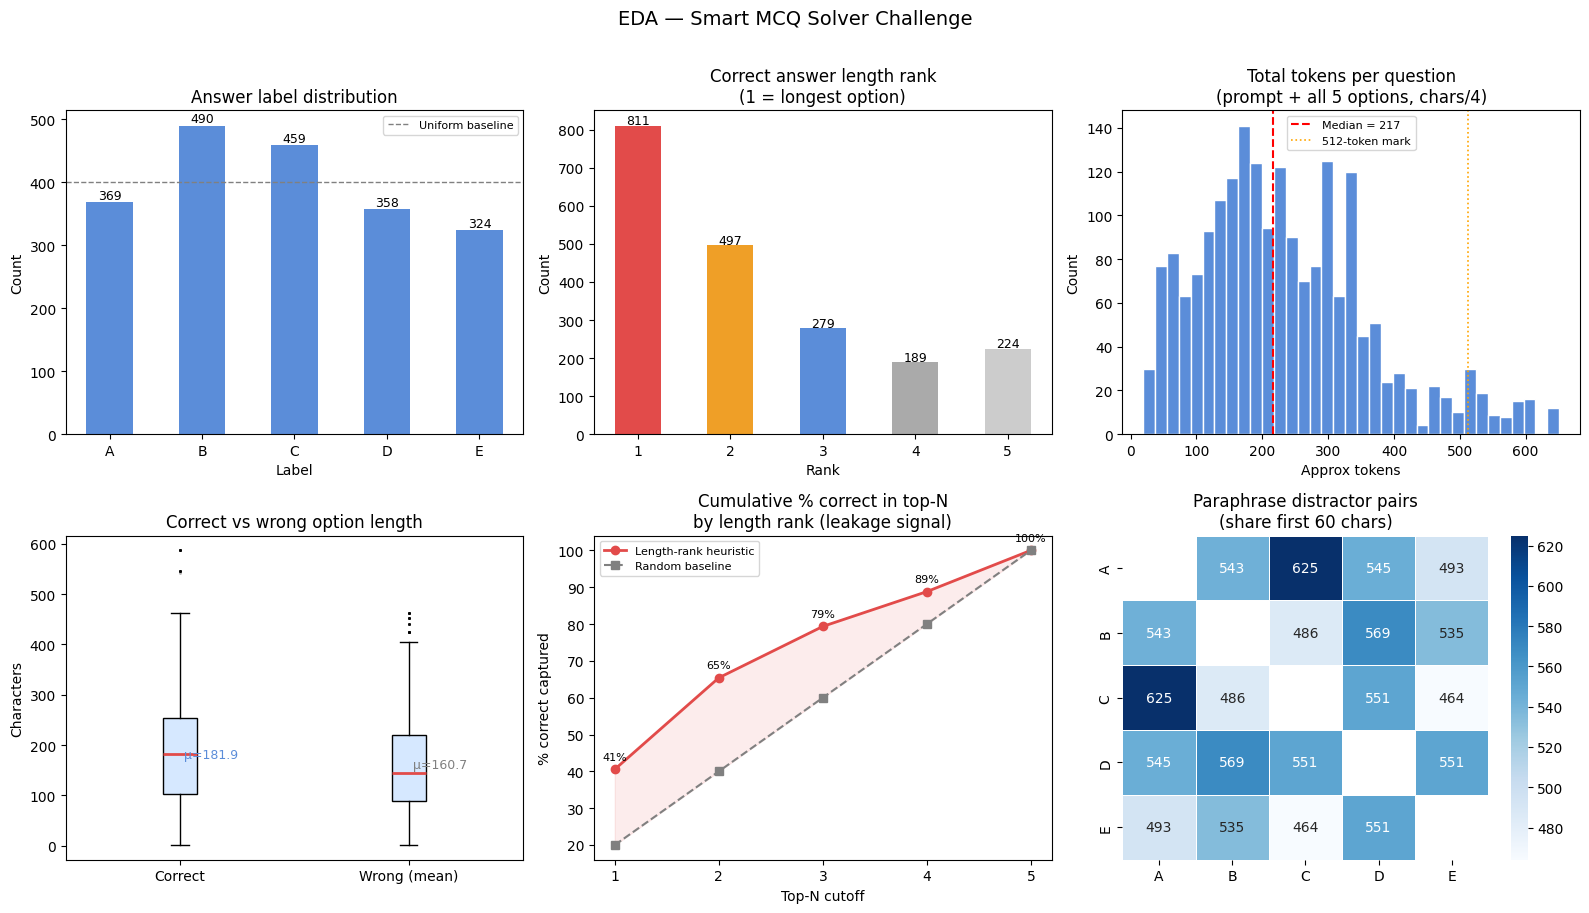

✓ EDA complete.


In [3]:
# ===========================================================
# EDA — Smart MCQ Solver  |  DL / GenAI notebook
# ===========================================================

import matplotlib.pyplot as plt
import seaborn as sns

OPTIONS = ["A", "B", "C", "D", "E"]
train = train_df.copy()

# -----------------------------------------------------------
# feature engineering
# -----------------------------------------------------------
for c in OPTIONS:
    train[f"{c}_len"] = train[c].str.len()

train["prompt_tokens"] = (train["prompt"].str.len() / 4).round().astype(int)  # 4 is approximate token length in english language normally
train["total_tokens"]  = (
    train["prompt_tokens"]
    + sum((train[f"{c}_len"] / 4).round().astype(int) for c in OPTIONS)
)

def correct_option_rank_by_length(row):
    lengths = {c: row[f"{c}_len"] for c in OPTIONS}
    return sorted(lengths, key=lengths.get, reverse=True).index(row["answer"]) + 1

train["correct_option_rank_by_length"] = train.apply(correct_option_rank_by_length, axis=1)
train["correct_option_len"] = train.apply(lambda r: r[f"{r['answer']}_len"], axis=1)
train["mean_wrong_len"]     = train.apply(
    lambda r: np.mean([r[f"{c}_len"] for c in OPTIONS if c != r["answer"]]), axis=1
)

# -----------------------------------------------------------
# overview print
# -----------------------------------------------------------
print("=" * 52)
print("  DATASET OVERVIEW")
print("=" * 52)
print(f"  Rows                  : {len(train):,}")
print(f"  Nulls                 : {train.isnull().sum().sum()}")
print(f"  Duplicate prompts     : {train.duplicated('prompt').sum()}")
print(f"  Unique option texts   : {pd.concat([train[c] for c in OPTIONS]).nunique():,} / {len(train)*5:,}")
print()
print("  Answer distribution:")
for label, cnt in train["answer"].value_counts().reindex(OPTIONS).items():
    print(f"    {label}  {cnt}  ({cnt/len(train)*100:.1f}%)")
print()
print(f"  Correct option avg len    : {train['correct_option_len'].mean():.1f} chars")
print(f"  Wrong  option avg len     : {train['mean_wrong_len'].mean():.1f} chars")
print(f"  longest option is correct : {(train['correct_option_rank_by_length']==1).mean()*100:.1f}% of the time")
print(f"  Avg total tokens/question : {train['total_tokens'].mean():.0f}  (max {train['total_tokens'].max()})")
print("=" * 52)

# -----------------------------------------------------------
# figures
# -----------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle("EDA — Smart MCQ Solver Challenge", fontsize=14, y=1.01)

# 1. answer label distribution
ans_counts = train["answer"].value_counts().reindex(OPTIONS)
axes[0, 0].bar(OPTIONS, ans_counts.values, color="#5B8DD9", width=0.5)
axes[0, 0].axhline(len(train) / 5, color="gray", lw=1, linestyle="--", label="Uniform baseline")
axes[0, 0].set_title("Answer label distribution")
axes[0, 0].set_xlabel("Label")
axes[0, 0].set_ylabel("Count")
axes[0, 0].legend(fontsize=8)
for i, v in enumerate(ans_counts.values):
    axes[0, 0].text(i, v + 5, str(v), ha="center", fontsize=9)

# 2. correct answer length rank
rank_counts = train["correct_option_rank_by_length"].value_counts().sort_index()
axes[0, 1].bar(rank_counts.index, rank_counts.values,
               color=["#E24B4A", "#EF9F27", "#5B8DD9", "#AAAAAA", "#CCCCCC"], width=0.5)
axes[0, 1].set_title("Correct answer length rank\n(1 = longest option)")
axes[0, 1].set_xlabel("Rank")
axes[0, 1].set_ylabel("Count")
for x, v in zip(rank_counts.index, rank_counts.values):
    axes[0, 1].text(x, v + 4, str(v), ha="center", fontsize=9)

# 3. total tokens per question
axes[0, 2].hist(train["total_tokens"], bins=35, color="#5B8DD9", edgecolor="white", lw=0.4)
axes[0, 2].axvline(train["total_tokens"].median(), color="red", lw=1.5,
                   linestyle="--", label=f"Median = {train['total_tokens'].median():.0f}")
axes[0, 2].axvline(512, color="orange", lw=1.2, linestyle=":", label="512-token mark")
axes[0, 2].set_title("Total tokens per question\n(prompt + all 5 options, chars/4)")
axes[0, 2].set_xlabel("Approx tokens")
axes[0, 2].set_ylabel("Count")
axes[0, 2].legend(fontsize=8)

# 4. correct vs wrong option length boxplot
axes[1, 0].boxplot(
    [train["correct_option_len"].values, train["mean_wrong_len"].values],
    labels=["Correct", "Wrong (mean)"],
    patch_artist=True,
    boxprops=dict(facecolor="#D6E8FF"),
    medianprops=dict(color="#E24B4A", linewidth=2),
    flierprops=dict(marker=".", markersize=2, alpha=0.3),
)
axes[1, 0].set_title("Correct vs wrong option length")
axes[1, 0].set_ylabel("Characters")
for x, col, val in [(1, "#5B8DD9", train["correct_option_len"].mean()),
                    (2, "gray",    train["mean_wrong_len"].mean())]:
    axes[1, 0].text(x, val, f" μ={val:.1f}", va="center", fontsize=9, color=col)

# 5. cumulative top-N by length rank vs random
cumulative      = [(train["correct_option_rank_by_length"] <= n).mean() * 100 for n in range(1, 6)]
random_baseline = [n / 5 * 100 for n in range(1, 6)]
axes[1, 1].plot(range(1, 6), cumulative, "o-", color="#E24B4A", lw=2, label="Length-rank heuristic")
axes[1, 1].plot(range(1, 6), random_baseline, "s--", color="gray", lw=1.5, label="Random baseline")
axes[1, 1].fill_between(range(1, 6), random_baseline, cumulative, alpha=0.1, color="#E24B4A")
axes[1, 1].set_title("Cumulative % correct in top-N\nby length rank (leakage signal)")
axes[1, 1].set_xlabel("Top-N cutoff")
axes[1, 1].set_ylabel("% correct captured")
axes[1, 1].set_xticks(range(1, 6))
axes[1, 1].legend(fontsize=8)
for x, y in zip(range(1, 6), cumulative):
    axes[1, 1].annotate(f"{y:.0f}%", (x, y), xytext=(0, 7),
                        textcoords="offset points", ha="center", fontsize=8)

# 6. pairwise paraphrase distractor heatmap
# for every pair of options across all 2000 questions,
# how many times they share the same first 60 characters.

sim = np.zeros((5, 5))
for i, a in enumerate(OPTIONS):
    for j, b in enumerate(OPTIONS):
        if i != j:
            sim[i][j] = (train[a].str[:60] == train[b].str[:60]).sum()
sns.heatmap(sim, annot=True, fmt=".0f", ax=axes[1, 2],
            xticklabels=OPTIONS, yticklabels=OPTIONS,
            cmap="Blues", mask=np.eye(5, dtype=bool),
            linewidths=0.4, annot_kws={"size": 10})
axes[1, 2].set_title("Paraphrase distractor pairs\n(share first 60 chars)")

plt.tight_layout()
plt.savefig("eda_mcq.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ EDA complete.")

In [4]:
# ===========================================================
# Dummy submission — length-rank heuristic based on EDA
# MAP@3: predict the 3 longest options per question
# ===========================================================

# ===========================================================
# Dummy submission — length-rank heuristic
# ===========================================================
# EDA finding: correct answer is the longest option in 40.6% of questions.
# Picking top-3 by length captures the correct answer 79.3% of the time.
#
# Note: this works because the dataset has a length bias (correct answers
# are consistently longer than distractors). A real model must learn
# semantics and score well beyond this heuristic.
# ===========================================================

OPTIONS = ["A", "B", "C", "D", "E"]

def top3_by_length(row):
    lengths = {c: len(row[c]) for c in OPTIONS}
    ranked  = sorted(lengths, key=lengths.get, reverse=True)
    return " ".join(ranked[:3])   # e.g. "B C A"

dummy_submission = pd.DataFrame({
    "ID":         test_df["id"],
    "Prediction": test_df.apply(top3_by_length, axis=1),
})

dummy_submission.to_csv("submission.csv", index=False)
print(dummy_submission.head(10).to_string(index=False))
print(f"\n✓ dummy submission.csv saved  ({len(dummy_submission)} rows)")

 ID Prediction
  1      D C A
  2      B E D
  3      E B C
  4      E C A
  5      E A D
  6      C D B
  7      B D E
  8      D A C
  9      E C D
 10      B E A

✓ dummy submission.csv saved  (500 rows)
